# Etapa 4 — CNN sobre espectrogramas y comparativa de optimizadores

El entrenamiento está en `scripts/entrenar_cnn.py` (en CPU tarda cerca de 2 horas); este notebook
explica el modelo y los optimizadores y analiza las corridas guardadas en `resultados/etapa4/corridas/`.

**Partición por paciente** (Etapa 2): entrenamiento chb02, chb05, chb08; validación chb01;
prueba chb03, chb10. El conjunto de prueba no se usa para elegir nada.

In [1]:
from pathlib import Path
import json
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
try:
    import google.colab  # noqa: F401
    RAIZ = Path("/content/drive/MyDrive/TP_Machine_Learning_Epilepsia")
except ImportError:
    RAIZ = Path.cwd().parents[0] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "scripts"))
import metricas as M
import entrenar_cnn as E
import estilo_graficos as EG
EG.aplicar()

BASE = RAIZ / "resultados" / "etapa4"
CORR = BASE / "corridas"
SALIDA = BASE
ORDEN = list(E.OPTIMIZADORES)
COLOR = EG.OPTIMIZADOR
print("RAIZ:", RAIZ)

RAIZ: D:\Universidad De Palermo - Maestria en IA\Machine Learning\TP_Machine_Learning_Epilepsia


## 4.1 Entrada y arquitectura

Cada ventana de 4 s es un tensor $\mathbf{X} \in \mathbb{R}^{18 \times 40 \times 7}$: el logaritmo del
espectrograma (STFT con ventana de Hann de 1 s y salto de 0,5 s) de 18 canales, en 40 frecuencias de
1 a 40 Hz y 7 instantes. Los canales del EEG se tratan como canales de entrada de la convolución.

Antes de entrar a la red, a cada paciente se le resta la mediana de su propio espectrograma por canal y
frecuencia (la misma calibración no supervisada que dio mejor resultado en la Etapa 3) y después se
estandariza con la media y el desvío del entrenamiento.

| Capa | Salida | Parámetros |
|---|---|---|
| Conv 5×3, 32 filtros + BatchNorm + ReLU + MaxPool (2,1) | 32 × 20 × 7 | 8 736 |
| Conv 3×3, 64 filtros + BatchNorm + ReLU + MaxPool (2,1) | 64 × 10 × 7 | 18 624 |
| Conv 3×3, 64 filtros + BatchNorm + ReLU | 64 × 10 × 7 | 37 056 |
| Promedio global + Dropout 0,3 + Lineal | 1 (logit) | 65 |

Salida: logit $z = f_{\boldsymbol\theta}(\mathbf{X})$, con $\hat p = \sigma(z)$. Pérdida de entropía cruzada binaria:

$$J(\boldsymbol\theta) = -\frac{1}{B}\sum_{i=1}^{B}\big[y_i \log \sigma(z_i) + (1-y_i)\log(1-\sigma(z_i))\big].$$

Esta pérdida **no es convexa** en $\boldsymbol\theta$ (Etapa 3, Parte B), así que el resultado depende del
optimizador, de la tasa de aprendizaje y de la inicialización.

**Desbalance.** En cada época se usan todas las ventanas con crisis del entrenamiento (≈ 400) y 10 veces
más ventanas sin crisis elegidas al azar, distintas en cada época. Así cada época tarda pocos segundos y
en 30 épocas el modelo ve ≈ 120 000 ventanas normales distintas.

In [2]:
modelo = E.CNN()
print(modelo)
print("parámetros entrenables:", sum(p.numel() for p in modelo.parameters() if p.requires_grad))

CNN(
  (red): Sequential(
    (0): Conv2d(18, 32, kernel_size=(5, 3), stride=(1, 1), padding=(2, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=(2, 1), stride=(2, 1), padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=(2, 1), stride=(2, 1), padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool2d(output_size=1)
    (12): Flatten(start_dim=1, end_dim=-1)
    (13): Dropout(p=0.3, inplace=False)
    (14): Linear(in_features=64, out_features=1, bias=True)
  )
)
parámetros entrenabl

## 4.2 Los seis optimizadores

Notación: $\mathbf{g}_t = \nabla_{\boldsymbol\theta} J_{B_t}(\boldsymbol\theta_t)$ es el gradiente sobre el lote $B_t$ de 64 ventanas,
$\eta$ la tasa de aprendizaje y $\lambda$ el decaimiento de pesos.

| Optimizador | Regla de actualización |
|---|---|
| **SGD** | $\boldsymbol\theta_{t+1} = \boldsymbol\theta_t - \eta\,(\mathbf{g}_t + \lambda\boldsymbol\theta_t)$ |
| **Momentum** (heavy ball) | $\mathbf{v}_{t+1} = \mu\mathbf{v}_t + \mathbf{g}_t,\quad \boldsymbol\theta_{t+1} = \boldsymbol\theta_t - \eta\,\mathbf{v}_{t+1}$, $\ \mu = 0{,}9$ |
| **Nesterov** | gradiente evaluado en el punto "adelantado" $\boldsymbol\theta_t - \eta\mu\mathbf{v}_t$; en la forma de PyTorch: $\boldsymbol\theta_{t+1} = \boldsymbol\theta_t - \eta(\mathbf{g}_t + \mu\mathbf{v}_{t+1})$ |
| **RMSprop** | $\mathbf{s}_{t+1} = \rho\,\mathbf{s}_t + (1-\rho)\,\mathbf{g}_t^2,\quad \boldsymbol\theta_{t+1} = \boldsymbol\theta_t - \eta\,\mathbf{g}_t / (\sqrt{\mathbf{s}_{t+1}} + \epsilon)$, $\ \rho = 0{,}99$ |
| **Adam** | $\mathbf{m}_{t+1} = \beta_1\mathbf{m}_t + (1-\beta_1)\mathbf{g}_t,\ \ \mathbf{s}_{t+1} = \beta_2\mathbf{s}_t + (1-\beta_2)\mathbf{g}_t^2$, <br> $\hat{\mathbf{m}} = \mathbf{m}_{t+1}/(1-\beta_1^{t+1}),\ \hat{\mathbf{s}} = \mathbf{s}_{t+1}/(1-\beta_2^{t+1}),\ \ \boldsymbol\theta_{t+1} = \boldsymbol\theta_t - \eta\,\hat{\mathbf{m}}/(\sqrt{\hat{\mathbf{s}}} + \epsilon)$ |
| **AdamW** | igual que Adam pero el decaimiento se aplica **separado** del gradiente adaptativo: $\boldsymbol\theta_{t+1} = (1 - \eta\lambda)\boldsymbol\theta_t - \eta\,\hat{\mathbf{m}}/(\sqrt{\hat{\mathbf{s}}} + \epsilon)$ |

Las operaciones con vectores ($\mathbf{g}^2$, la raíz, la división) son elemento a elemento.

**Ideas detrás de cada uno:**

- **Momentum** promedia los gradientes con peso exponencial: en direcciones donde el gradiente cambia de
  signo (valles angostos) se cancela, y en las direcciones consistentes acumula velocidad. En una cuadrática
  con número de condición $\kappa$ la tasa de convergencia pasa de $\frac{\kappa - 1}{\kappa + 1}$ (gradiente)
  a $\frac{\sqrt\kappa - 1}{\sqrt\kappa + 1}$ con los parámetros óptimos.
- **Nesterov** corrige la velocidad mirando el gradiente donde va a caer, no donde está; reduce la oscilación.
- **RMSprop y Adam** dividen cada coordenada por una estimación de la magnitud de su gradiente: es un
  precondicionador diagonal que hace el paso aproximadamente invariante a la escala de cada parámetro.
  Adam suma momento y corrige el sesgo inicial de los promedios ($\mathbf{m}_0 = \mathbf{s}_0 = 0$).
- **AdamW**: en Adam, sumar $\lambda\boldsymbol\theta$ al gradiente no equivale a regularización L2, porque ese
  término también se divide por $\sqrt{\hat{\mathbf{s}}}$: los parámetros con gradientes grandes casi no se
  regularizan. AdamW aplica el decaimiento directamente sobre los pesos (Loshchilov y Hutter, 2019).

**Diseño experimental.**

1. **Búsqueda de tasa de aprendizaje:** cada optimizador se prueba con 3 valores de $\eta$ (las escalas
   típicas son distintas: SGD sin momento usa $\eta$ más grande; los adaptativos, más chico), semilla 0,
   30 épocas. Se elige el $\eta$ con mejor AUC de validación.
2. **Semillas:** con el $\eta$ elegido, 5 semillas por optimizador (inicialización y orden de los lotes).
   Se informa media y desvío, porque con una pérdida no convexa una sola corrida no alcanza para comparar.
3. En cada corrida se guarda el modelo de la época con mejor AUC de validación (*early stopping*).

In [3]:
def leer_corridas():
    filas, hist = [], []
    for f in sorted(CORR.glob("*.json")):
        r = json.loads(f.read_text(encoding="utf-8"))
        filas.append({k: r.get(k) for k in ["optimizador", "lr", "semilla", "mejor_epoca", "auc_val_mejor",
                                            "auc_val_completo", "auc_prueba", "diverge", "segundos", "parametros"]})
        for h in r["historia"]:
            hist.append({"optimizador": r["optimizador"], "lr": r["lr"], "semilla": r["semilla"], **h})
    return pd.DataFrame(filas), pd.DataFrame(hist)

todas, historia = leer_corridas()
elegidas = json.loads((BASE / "lr_elegidas.json").read_text(encoding="utf-8"))
# Diseño original: búsqueda (semilla 0, 3 tasas) + 5 semillas con la tasa elegida. Las corridas extra del
# experimento de sensibilidad (fase posthoc) se analizan aparte, al final de la sección 4.4.
original = (todas.semilla == 0) | todas.apply(lambda r: r.lr == elegidas[r.optimizador], axis=1)
corridas = todas[original].reset_index(drop=True)
print(len(todas), "corridas en total;", len(corridas), "del diseño original")
corridas.groupby("optimizador").size()

62 corridas en total; 42 del diseño original


optimizador
Adam        7
AdamW       7
Momentum    7
Nesterov    7
RMSprop     7
SGD         7
dtype: int64

## 4.3 Búsqueda de la tasa de aprendizaje (semilla 0)

In [4]:
busq = corridas[corridas.semilla == 0].pivot_table(index="optimizador", columns="lr", values="auc_val_mejor").reindex(ORDEN)
busq.round(4).to_csv(SALIDA / "busqueda_lr.csv")
print("tasas elegidas:", elegidas)
busq.round(4)

tasas elegidas: {'SGD': 0.3, 'Momentum': 0.01, 'Nesterov': 0.003, 'RMSprop': 0.0003, 'Adam': 0.0003, 'AdamW': 0.0003}


lr,0.0003,0.0010,0.0030,0.0100,0.0300,0.1000,0.3000
optimizador,,,,,,,
SGD,NaN,NaN,NaN,NaN,0.9987,0.999,0.9992
Momentum,NaN,NaN,0.9991,0.9992,0.9981,NaN,NaN
Nesterov,NaN,NaN,0.9990,0.9981,0.9988,NaN,NaN
RMSprop,0.9983,0.9980,0.9977,NaN,NaN,NaN,NaN
Adam,0.9994,0.9983,0.9987,NaN,NaN,NaN,NaN
AdamW,0.9994,0.9983,0.9975,NaN,NaN,NaN,NaN


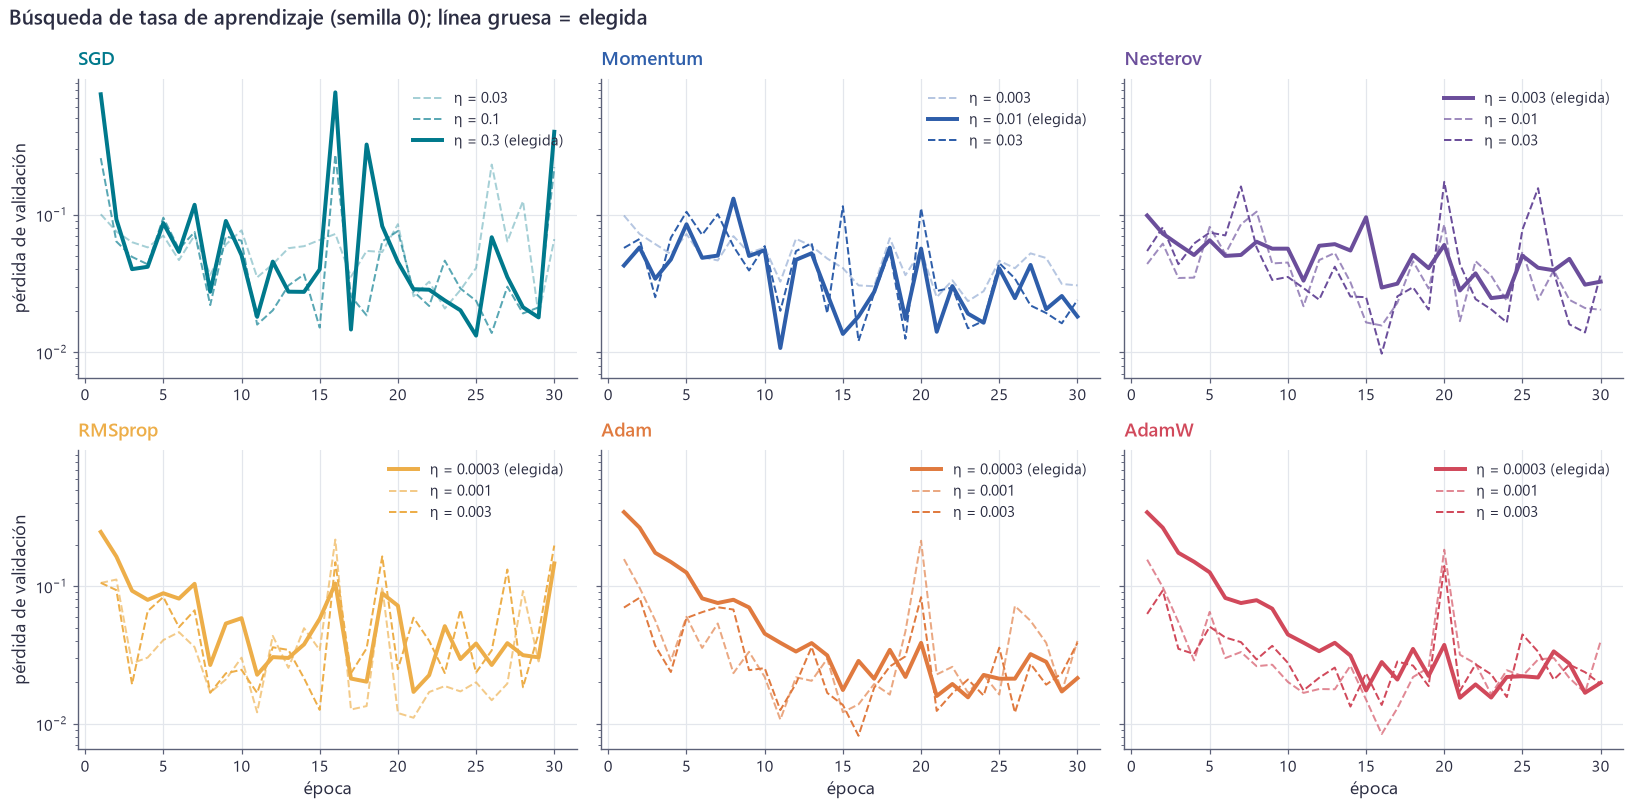

In [5]:
fig, ejes = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
for ax, opt in zip(ejes.ravel(), ORDEN):
    tonos = [0.35, 0.65, 1.0]
    for lr, a_ in zip(sorted(E.OPTIMIZADORES[opt][0]), tonos):
        h = historia[(historia.optimizador == opt) & (historia.lr == lr) & (historia.semilla == 0)]
        es = lr == elegidas[opt]
        ax.plot(h.epoca, h.perdida_val, lw=2.6 if es else 1.3, color=COLOR[opt], alpha=a_ if not es else 1,
                ls="-" if es else "--", label=f"η = {lr:g}" + (" (elegida)" if es else ""))
    ax.set_title(opt, color=COLOR[opt]); ax.set_yscale("log"); ax.legend(fontsize=9.5)
for ax in ejes[1]:
    ax.set_xlabel("época")
for ax in ejes[:, 0]:
    ax.set_ylabel("pérdida de validación")
fig.suptitle("Búsqueda de tasa de aprendizaje (semilla 0); línea gruesa = elegida", x=0.01, ha="left",
             fontsize=13.5, fontweight="semibold")
fig.tight_layout(); fig.savefig(SALIDA / "busqueda_lr_curvas.png")

## 4.4 Comparativa con 5 semillas

In [6]:
sel = corridas[corridas.apply(lambda r: r.lr == elegidas[r.optimizador], axis=1)]
comp = (sel.groupby("optimizador")
        .agg(lr=("lr", "first"), semillas=("semilla", "nunique"),
             auc_val_media=("auc_val_completo", "mean"), auc_val_desvio=("auc_val_completo", "std"),
             auc_prueba_media=("auc_prueba", "mean"), auc_prueba_desvio=("auc_prueba", "std"),
             auc_prueba_min=("auc_prueba", "min"), auc_prueba_max=("auc_prueba", "max"),
             mejor_epoca_mediana=("mejor_epoca", "median"), segundos_media=("segundos", "mean"))
        .reindex(ORDEN))
comp.round(4).to_csv(SALIDA / "comparativa_optimizadores.csv")
comp.round(4)

,lr,semillas,auc_val_media,auc_val_desvio,auc_prueba_media,auc_prueba_desvio,auc_prueba_min,auc_prueba_max,mejor_epoca_mediana,segundos_media
optimizador,,,,,,,,,,
SGD,0.3000,5,0.9982,0.0006,0.9758,0.0063,0.9657,0.9808,26.0,93.6893
Momentum,0.0100,5,0.9984,0.0004,0.9191,0.0341,0.8749,0.9565,16.0,92.4418
Nesterov,0.0030,5,0.9980,0.0014,0.9196,0.0388,0.8543,0.9568,24.0,92.4391
RMSprop,0.0003,5,0.9982,0.0004,0.9562,0.0224,0.9263,0.9775,11.0,92.4535
Adam,0.0003,5,0.9986,0.0004,0.9171,0.0278,0.8707,0.9394,16.0,94.0837
AdamW,0.0003,5,0.9986,0.0004,0.9225,0.0330,0.8728,0.9603,16.0,93.0574


### Curvas de entrenamiento (mediana y rango intercuartil sobre las 5 semillas)

Se usa la mediana y no la media porque algunas épocas aisladas tienen picos de pérdida (lotes con
pocas crisis) que en escala logarítmica dominan la media. El AUC de validación se muestra como
$1 - \text{AUC}$ en escala logarítmica para que se vean las diferencias cerca de 1.

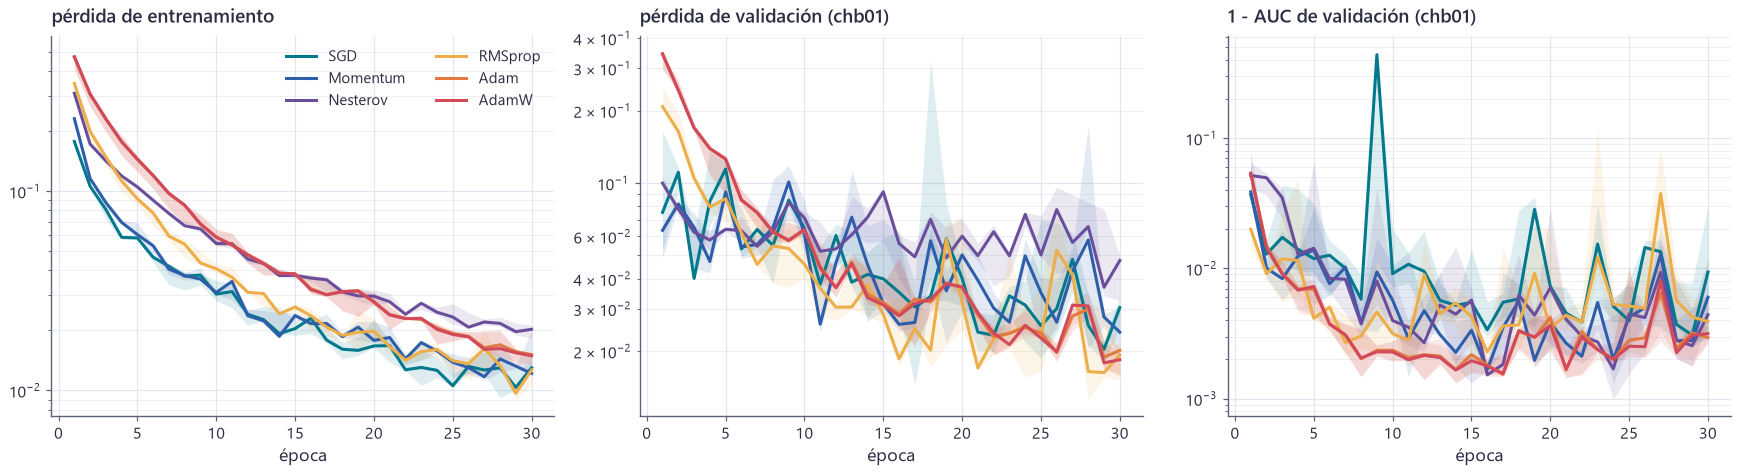

In [7]:
hs = historia.merge(sel[["optimizador", "lr", "semilla"]], on=["optimizador", "lr", "semilla"])
hs = hs.assign(error_auc_val=1 - hs.auc_val)
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
for opt in ORDEN:
    g = hs[hs.optimizador == opt].groupby("epoca")
    for ax, col in zip(ejes, ["perdida_entrenamiento", "perdida_val", "error_auc_val"]):
        med, q1, q3 = g[col].median(), g[col].quantile(0.25), g[col].quantile(0.75)
        ax.plot(med.index, med, color=COLOR[opt], label=opt, lw=2)
        ax.fill_between(med.index, q1, q3, color=COLOR[opt], alpha=0.13, lw=0)
for ax, t in zip(ejes, ["pérdida de entrenamiento", "pérdida de validación (chb01)", "1 - AUC de validación (chb01)"]):
    ax.set_yscale("log"); ax.set_title(t); ax.set_xlabel("época")
    ax.grid(which="minor", color=EG.GRIS_CLARO, lw=0.4)
ejes[0].legend(ncol=2)
fig.tight_layout(); fig.savefig(SALIDA / "curvas_optimizadores.png")

**Observaciones:**
- **Pérdida de entrenamiento:** SGD y Momentum bajan más rápido; Nesterov, Adam y AdamW quedan más
  arriba. No es una propiedad del algoritmo sino de la tasa elegida: para esos tres la búsqueda eligió
  la tasa **más chica** de su grilla.
- **SGD con $\eta = 0{,}3$ está cerca del límite de estabilidad:** en las 5 semillas hay épocas sueltas
  en las que el AUC de validación cae de golpe por debajo de 0,7 (mínimo 0,21) y se recupera en la época
  siguiente. En la mediana se ve como el pico de la época 9. Guardar el modelo de la mejor época (*early stopping*) evita que esos saltos afecten
  el resultado final.
- **Desde la época 8, todos los optimizadores quedan con $1 - \text{AUC} \approx 2\times10^{-3}$ en
  validación.** chb01 es un paciente "fácil" para todos los modelos: la validación queda **saturada** y no
  distingue entre optimizadores (se analiza más abajo).

### Distribución del AUC de prueba por semilla

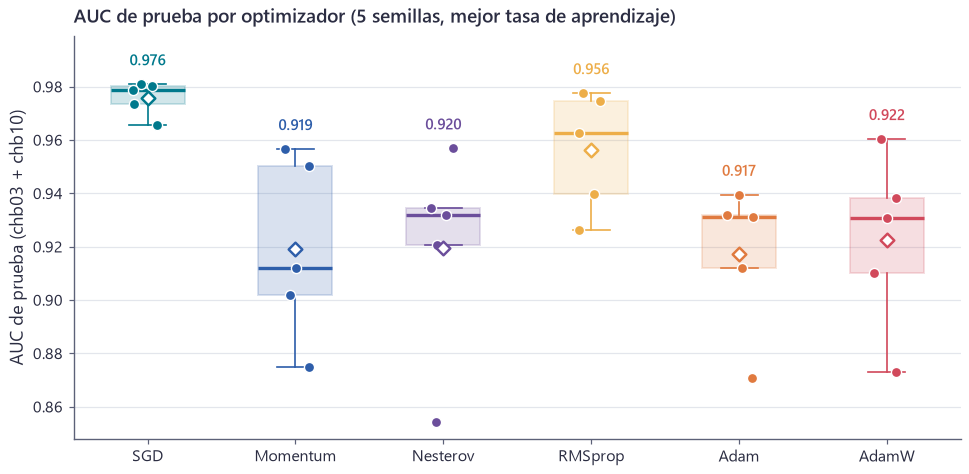

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
datos = [sel[sel.optimizador == o].auc_prueba.values for o in ORDEN]
cajas = ax.boxplot(datos, tick_labels=ORDEN, widths=0.5, showfliers=False, patch_artist=True,
                   medianprops=dict(lw=2.2), whiskerprops=dict(lw=1.1), capprops=dict(lw=1.1))
for k, d in enumerate(datos):
    c = COLOR[ORDEN[k]]
    cajas["boxes"][k].set(facecolor=c, alpha=0.18, edgecolor=c, lw=1.3)
    cajas["medians"][k].set(color=c)
    for parte in ("whiskers", "caps"):
        for ln in cajas[parte][2 * k: 2 * k + 2]:
            ln.set(color=c)
    ax.scatter(np.full(len(d), k + 1) + np.random.default_rng(k).uniform(-0.1, 0.1, len(d)), d,
               color=c, zorder=3, s=44, edgecolors="white", linewidths=0.9)
    ax.scatter(k + 1, d.mean(), marker="D", s=40, color="white", edgecolors=c, lw=1.6, zorder=4)
    ax.text(k + 1, d.max() + 0.006, f"{d.mean():.3f}", ha="center", va="bottom", fontsize=9.5, color=c,
            fontweight="semibold")
ax.set_ylim(top=max(d.max() for d in datos) + 0.018)
ax.set_ylabel("AUC de prueba (chb03 + chb10)"); ax.grid(axis="x", visible=False)
ax.set_title("AUC de prueba por optimizador (5 semillas, mejor tasa de aprendizaje)")
fig.tight_layout(); fig.savefig(SALIDA / "auc_prueba_por_optimizador.png")

### ¿Las diferencias son significativas?

Con 5 semillas por optimizador, se compara cada uno contra el mejor con la prueba de Mann–Whitney
(no supone normalidad). Con $n = 5$ por grupo, el $p$ mínimo posible (dos colas) es $2/\binom{10}{5} \approx 0{,}008$.

In [9]:
from scipy.stats import mannwhitneyu
mejor = comp.auc_prueba_media.idxmax()
pruebas = []
for o in ORDEN:
    if o == mejor:
        continue
    st = mannwhitneyu(sel[sel.optimizador == mejor].auc_prueba, sel[sel.optimizador == o].auc_prueba, alternative="two-sided")
    pruebas.append({"comparacion": f"{mejor} vs {o}", "U": st.statistic, "p_valor": st.pvalue})
pruebas = pd.DataFrame(pruebas).round(4)
pruebas.to_csv(SALIDA / "mann_whitney.csv", index=False)
pruebas

,comparacion,U,p_valor
0,SGD vs Momentum,25.0,0.0079
1,SGD vs Nesterov,25.0,0.0079
2,SGD vs RMSprop,21.0,0.0952
3,SGD vs Adam,25.0,0.0079
4,SGD vs AdamW,25.0,0.0079


**Observaciones:**
- **SGD con $\eta = 0{,}3$ es el mejor en prueba y además el más estable:** AUC 0,976 ± 0,006, y su
  peor semilla (0,966) supera a la mejor semilla de Adam (0,939).
- La diferencia con Momentum, Nesterov, Adam y AdamW es la **máxima posible** con 5 semillas por grupo
  (las 5 de SGD superan a las 5 del otro: $U = 25$, $p = 0{,}0079$). Con 5 comparaciones, la corrección de
  Bonferroni pide $p < 0{,}01$, así que la diferencia se mantiene. Contra RMSprop no es significativa
  ($p = 0{,}095$).
- A primera vista coincide con Wilson et al. (2017), que observaron que los métodos adaptativos
  generalizan peor que SGD. **Pero la comparación es entre optimizadores, cada uno con su tasa elegida,**
  y las secciones siguientes muestran que esa elección falló. Con la tasa más alta, la ventaja de SGD
  sobre los adaptativos desaparece.

### Análisis a posteriori: ¿la validación elige bien?

Esta sección **mira la prueba** y por eso no se usa para elegir nada: solo sirve para entender por qué
el ranking de validación y el de prueba no coinciden.

Para comparar optimizadores con y sin momento se usa el **paso efectivo**. Con momento $\mu$ y gradiente
aproximadamente constante, la velocidad tiende a $\mathbf{g}/(1-\mu)$, así que el paso es
$\eta_\text{ef} = \eta/(1-\mu)$, o sea $10\,\eta$ con $\mu = 0{,}9$. En los adaptativos la escala es otra
(el paso por coordenada es $\approx \eta$), y por eso solo se comparan entre sí.

AUC de PRUEBA por tasa (semilla 0):
lr           0.0003  0.0010  0.0030  0.0100  0.0300  0.1000  0.3000
optimizador                                                        
SGD             NaN     NaN     NaN     NaN   0.936   0.948    0.98
Momentum        NaN     NaN   0.905   0.912   0.959     NaN     NaN
Nesterov        NaN     NaN   0.854   0.886   0.962     NaN     NaN
RMSprop       0.926   0.979   0.970     NaN     NaN     NaN     NaN
Adam          0.871   0.920   0.977     NaN     NaN     NaN     NaN
AdamW         0.873   0.863   0.962     NaN     NaN     NaN     NaN

Spearman AUC validación vs AUC prueba (42 corridas): rho = -0.30, p = 0.06
rango del AUC de validación: 0.9956 - 0.9993
rango del AUC de prueba:     0.8543 - 0.9808


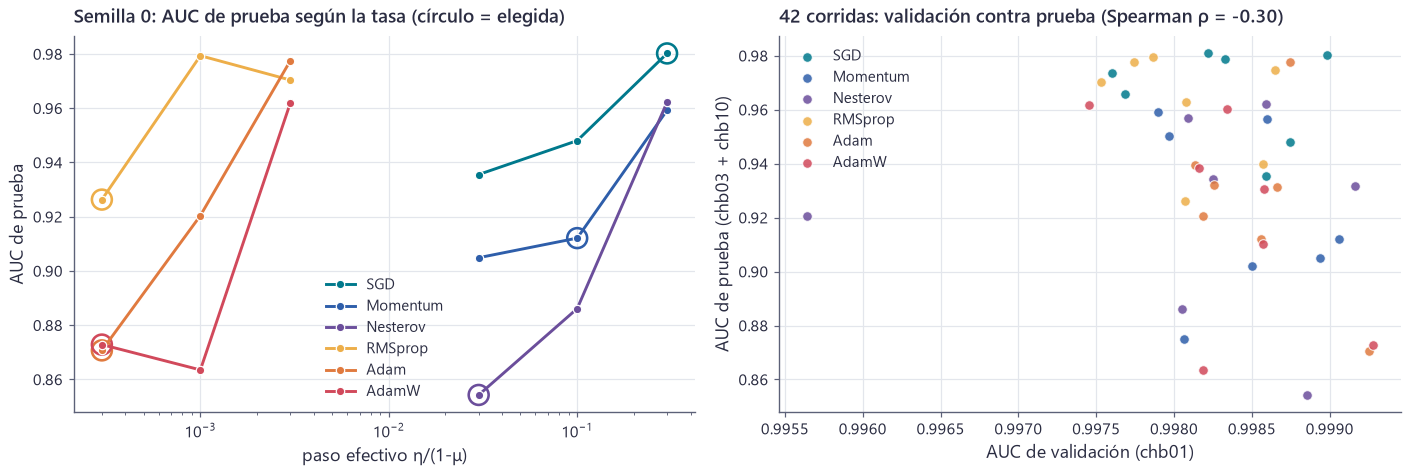

In [10]:
b0 = corridas[corridas.semilla == 0].copy()
b0["paso_efectivo"] = np.where(b0.optimizador.isin(["Momentum", "Nesterov"]), b0.lr * 10, b0.lr)
b0["elegida"] = b0.apply(lambda r: r.lr == elegidas[r.optimizador], axis=1)
tabla_post = b0.pivot_table(index="optimizador", columns="lr", values="auc_prueba").reindex(ORDEN)
tabla_post.round(4).to_csv(SALIDA / "busqueda_lr_auc_prueba.csv")
print("AUC de PRUEBA por tasa (semilla 0):")
print(tabla_post.round(3).to_string())

from scipy.stats import spearmanr
rho_vp = spearmanr(corridas.auc_val_completo, corridas.auc_prueba)
print(f"\nSpearman AUC validación vs AUC prueba ({len(corridas)} corridas): rho = {rho_vp.statistic:.2f}, p = {rho_vp.pvalue:.2f}")
print(f"rango del AUC de validación: {corridas.auc_val_completo.min():.4f} - {corridas.auc_val_completo.max():.4f}")
print(f"rango del AUC de prueba:     {corridas.auc_prueba.min():.4f} - {corridas.auc_prueba.max():.4f}")

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for opt in ORDEN:
    d = b0[b0.optimizador == opt].sort_values("lr")
    ejes[0].plot(d.paso_efectivo, d.auc_prueba, "o-", color=COLOR[opt], label=opt,
                 markeredgecolor="white", markeredgewidth=0.8)
    e = d[d.elegida]
    ejes[0].scatter(e.paso_efectivo, e.auc_prueba, s=170, facecolors="none", edgecolors=COLOR[opt], lw=1.7)
    d = corridas[corridas.optimizador == opt]
    ejes[1].scatter(d.auc_val_completo, d.auc_prueba, color=COLOR[opt], s=40, alpha=0.85,
                    edgecolors="white", linewidths=0.7, label=opt)
ejes[0].set_xscale("log"); ejes[0].set_xlabel("paso efectivo η/(1-μ)"); ejes[0].set_ylabel("AUC de prueba")
ejes[0].set_title("Semilla 0: AUC de prueba según la tasa (círculo = elegida)")
ejes[1].set_xlabel("AUC de validación (chb01)"); ejes[1].set_ylabel("AUC de prueba (chb03 + chb10)")
ejes[1].set_title(f"{len(corridas)} corridas: validación contra prueba (Spearman ρ = {rho_vp.statistic:.2f})")
for ax in ejes:
    ax.legend(fontsize=9.5)
fig.tight_layout(); fig.savefig(SALIDA / "validacion_vs_prueba.png")

**Observaciones:**
- **La validación no predice la prueba.** El AUC de validación de las 42 corridas varía entre 0,9956 y
  0,9993 (diferencias de milésimas, del orden del ruido entre semillas), mientras que el de prueba va de
  0,854 a 0,981. La correlación de rangos es incluso **negativa** ($\rho = -0{,}30$, $p = 0{,}06$).
- **La búsqueda eligió la tasa equivocada en 5 de 6 optimizadores.** En la semilla 0, la tasa **más
  alta** de la grilla dio el mejor AUC de prueba en SGD, Momentum, Nesterov, Adam y AdamW (RMSprop: la
  del medio). La validación, en cambio, eligió la más chica para Nesterov, RMSprop, Adam y AdamW.
- Con la tasa más alta, los demás optimizadores también superan 0,95 en la semilla 0. Entonces la
  ventaja de SGD en la tabla anterior puede deberse a que a SGD le tocó una tasa alta y no al algoritmo.
  Una explicación conocida: con pasos grandes, el ruido del gradiente estocástico impide quedarse en
  mínimos angostos y empuja hacia regiones más planas, que suelen generalizar mejor. Esa hipótesis se
  prueba más abajo con un experimento de sensibilidad.
- **Lección de diseño:** un solo paciente de validación no alcanza. Con datos de pocos pacientes,
  conviene validación cruzada por paciente (como el LOPO de la Etapa 3) también para elegir
  hiperparámetros, aunque multiplique el costo de entrenamiento.

### ¿De dónde salen las diferencias en prueba?

Para cada corrida y cada crisis de prueba se calcula el **percentil** del puntaje mediano de sus ventanas
respecto de las ventanas sin crisis de prueba: 1 significa que la crisis queda por encima de todas las
ventanas normales; 0,5, que no se distingue de ellas.

Desvío del percentil entre las 42 corridas, por crisis:
chb03_01    0.003
chb03_02    0.003
chb03_03    0.001
chb03_04    0.001
chb03_34    0.281
chb03_35    0.207
chb03_36    0.295
chb10_12    0.003
chb10_20    0.000
chb10_27    0.000
chb10_30    0.049
chb10_31    0.000
chb10_38    0.000
chb10_89    0.033

Spearman entre el AUC de prueba y el percentil medio de chb03_34-36: 0.87


,auc_prueba,AUC_chb03,AUC_chb10,percentil_tardias
optimizador,,,,
SGD,0.974,0.947,0.990,0.965
Momentum,0.912,0.838,0.974,0.764
Nesterov,0.932,0.880,0.983,0.932
RMSprop,0.970,0.945,0.988,0.967
Adam,0.931,0.856,0.983,0.858
AdamW,0.931,0.865,0.982,0.890


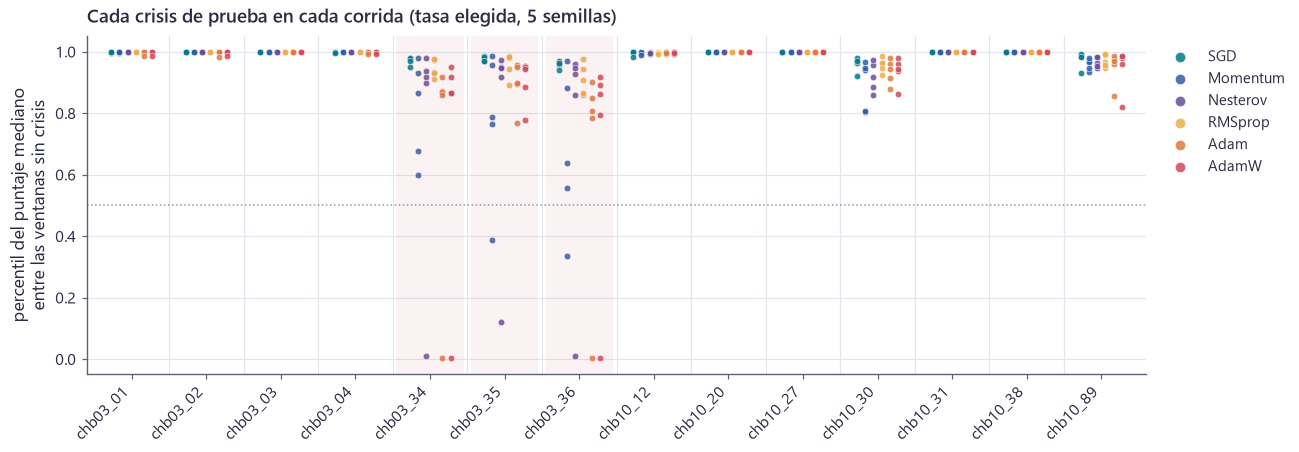

In [11]:
Vp = dict(np.load(BASE / "ventanas_prueba.npz"))
lim_p = Vp["borde"] == 0
y_p, pac_p, arch_p = Vp["ictal"][lim_p] == 1, Vp["paciente"][lim_p], Vp["archivo"][lim_p]
ARCH_CRISIS = list(pd.unique(arch_p[y_p]))
filas = []
for _, r in corridas.iterrows():
    s = np.load(CORR / f"{r.optimizador}_lr{r.lr:g}_s{int(r.semilla)}_scores.npz")["prueba"][lim_p]
    neg = np.sort(s[~y_p])
    fila = {"optimizador": r.optimizador, "lr": r.lr, "semilla": r.semilla, "auc_prueba": r.auc_prueba,
            **{f"AUC_{p}": roc_auc_score(y_p[pac_p == p], s[pac_p == p]) for p in np.unique(pac_p)}}
    for a in ARCH_CRISIS:
        fila[a.replace(".edf", "")] = np.searchsorted(neg, np.median(s[y_p & (arch_p == a)])) / len(neg)
    filas.append(fila)
por_crisis = pd.DataFrame(filas)
por_crisis.round(4).to_csv(SALIDA / "percentil_por_crisis.csv", index=False)

cols_c = [a.replace(".edf", "") for a in ARCH_CRISIS]
print(f"Desvío del percentil entre las {len(corridas)} corridas, por crisis:")
print(por_crisis[cols_c].std().round(3).to_string())
tardias = ["chb03_34", "chb03_35", "chb03_36"]
por_crisis["percentil_tardias"] = por_crisis[tardias].mean(axis=1)
rho_t = spearmanr(por_crisis.percentil_tardias, por_crisis.auc_prueba).statistic
print(f"\nSpearman entre el AUC de prueba y el percentil medio de chb03_34-36: {rho_t:.2f}")

fig, ax = plt.subplots(figsize=(12, 4.3))
pos = np.arange(len(cols_c))
for k, opt in enumerate(ORDEN):
    d = por_crisis[(por_crisis.optimizador == opt) & (por_crisis.lr == elegidas[opt])]
    ax.scatter(np.repeat(pos, len(d)) + (k - 2.5) * 0.11, d[cols_c].to_numpy().T.ravel(), s=18,
               color=COLOR[opt], alpha=0.85, edgecolors="white", linewidths=0.4, label=opt)
for j, cc in enumerate(cols_c):
    if cc in tardias:
        ax.axvspan(j - 0.45, j + 0.45, color=EG.ROJO, alpha=0.07, lw=0)
for j in pos[:-1]:
    ax.axvline(j + 0.5, color=EG.GRIS_CLARO, lw=0.8)
ax.set_xticks(pos, cols_c, rotation=45, ha="right"); ax.axhline(0.5, c=EG.GRIS, ls=":", lw=1)
ax.set_xlim(-0.6, len(cols_c) - 0.4); ax.grid(axis="x", visible=False)
ax.set_ylabel("percentil del puntaje mediano\nentre las ventanas sin crisis")
ax.set_title("Cada crisis de prueba en cada corrida (tasa elegida, 5 semillas)")
ax.legend(loc="upper left", bbox_to_anchor=(1.005, 1.0), markerscale=1.6)
fig.tight_layout(); fig.savefig(SALIDA / "percentil_por_crisis.png")
por_crisis.groupby("optimizador")[["auc_prueba", "AUC_chb03", "AUC_chb10", "percentil_tardias"]].median().reindex(ORDEN).round(3)

**Observaciones:**
- **11 de las 14 crisis de prueba las detectan bien todas las corridas** (percentil > 0,8 en casi todos
  los casos, desvío entre corridas < 0,05). Las diferencias entre optimizadores salen casi enteras de
  **tres crisis de un mismo paciente**: chb03_34, chb03_35 y chb03_36, con desvío entre corridas de 0,2 a 0,3.
- El percentil medio de esas tres crisis explica el ranking de prueba: correlación de Spearman de 0,87
  con el AUC de prueba.
- En algunas corridas, entre ellas el modelo elegido (AdamW, semilla 0), esas crisis quedan **por debajo
  de casi todas las ventanas normales** (percentil ≈ 0). Esto explica la meseta de la ROC de la sección 4.6.
- **Consecuencia para la comparativa:** el "conjunto de prueba efectivo" para distinguir optimizadores
  son 3 crisis de un paciente. Las conclusiones sobre optimizadores no se pueden generalizar mucho más
  allá de este caso.

### Experimento de sensibilidad: todos con su tasa más alta

La búsqueda sugiere que la diferencia entre optimizadores puede deberse a la **tasa elegida** y no al
algoritmo. Para probarlo, cada optimizador se corre con la tasa más alta de su grilla y 5 semillas
(`entrenar_cnn.py posthoc`). Este experimento se diseñó **después de mirar la prueba**, así que es
exploratorio: no cambia el modelo elegido ni los resultados de la sección 4.5.

,lr,semillas,auc_val_media,auc_prueba_media,auc_prueba_desvio,auc_prueba_min,auc_prueba_tasa_elegida
optimizador,,,,,,,
SGD,0.300,5,0.9982,0.9758,0.0063,0.9657,0.9758
Momentum,0.030,5,0.9979,0.9596,0.0067,0.9499,0.9191
Nesterov,0.030,5,0.9987,0.9501,0.0285,0.9047,0.9196
RMSprop,0.003,5,0.9976,0.9730,0.0132,0.9516,0.9562
Adam,0.003,5,0.9984,0.9712,0.0091,0.9570,0.9171
AdamW,0.003,5,0.9975,0.9699,0.0076,0.9619,0.9225


,comparacion,U,p_valor
0,SGD vs Momentum (tasa alta),24.0,0.0159
1,SGD vs Nesterov (tasa alta),22.0,0.0556
2,SGD vs RMSprop (tasa alta),13.0,1.0000
3,SGD vs Adam (tasa alta),18.0,0.3095
4,SGD vs AdamW (tasa alta),19.0,0.2222


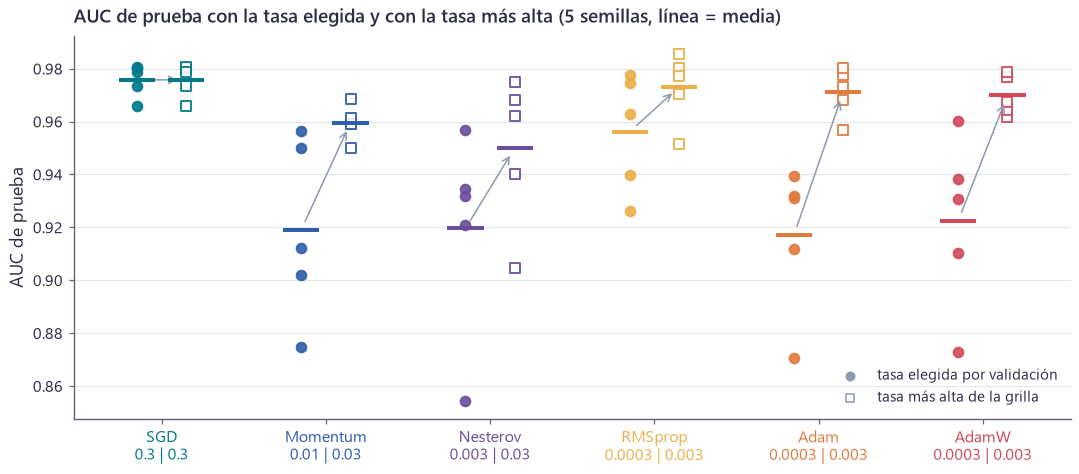

In [12]:
alta = {o: max(E.OPTIMIZADORES[o][0]) for o in ORDEN}
sel_alta = todas[todas.apply(lambda r: r.lr == alta[r.optimizador], axis=1)]
comp_alta = (sel_alta.groupby("optimizador")
             .agg(lr=("lr", "first"), semillas=("semilla", "nunique"),
                  auc_val_media=("auc_val_completo", "mean"),
                  auc_prueba_media=("auc_prueba", "mean"), auc_prueba_desvio=("auc_prueba", "std"),
                  auc_prueba_min=("auc_prueba", "min"))
             .reindex(ORDEN))
comp_alta["auc_prueba_tasa_elegida"] = comp.auc_prueba_media
comp_alta.round(4).to_csv(SALIDA / "comparativa_tasa_alta.csv")

pr_alta = []
for o in ORDEN:
    if o == "SGD":
        continue
    st = mannwhitneyu(sel_alta[sel_alta.optimizador == "SGD"].auc_prueba, sel_alta[sel_alta.optimizador == o].auc_prueba,
                      alternative="two-sided")
    pr_alta.append({"comparacion": f"SGD vs {o} (tasa alta)", "U": st.statistic, "p_valor": st.pvalue})
pr_alta = pd.DataFrame(pr_alta).round(4)
pr_alta.to_csv(SALIDA / "mann_whitney_tasa_alta.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.5))
for k, o in enumerate(ORDEN):
    for dx, df_, mk in [(-0.15, sel, "o"), (0.15, sel_alta, "s")]:
        d = df_[df_.optimizador == o].auc_prueba.values
    medias = []
    for dx, df_, mk in [(-0.15, sel, "o"), (0.15, sel_alta, "s")]:
        d = df_[df_.optimizador == o].auc_prueba.values
        ax.scatter(np.full(len(d), k + dx), d, edgecolors=COLOR[o], marker=mk, s=40, lw=1.3,
                   facecolors="white" if mk == "s" else COLOR[o], alpha=0.9, zorder=3)
        ax.hlines(d.mean(), k + dx - 0.11, k + dx + 0.11, color=COLOR[o], lw=2.6, zorder=4)
        medias.append(d.mean())
    ax.annotate("", (k + 0.15, medias[1]), (k - 0.15, medias[0]),
                arrowprops=dict(arrowstyle="->", color=EG.GRIS, lw=1, shrinkA=6, shrinkB=6))
ax.scatter([], [], c=EG.GRIS, marker="o", label="tasa elegida por validación")
ax.scatter([], [], facecolors="white", edgecolors=EG.GRIS, marker="s", label="tasa más alta de la grilla")
ax.set_xticks(range(len(ORDEN)), [f"{o}\n{elegidas[o]:g} | {alta[o]:g}" for o in ORDEN])
for etq, o in zip(ax.get_xticklabels(), ORDEN):
    etq.set_color(COLOR[o])
ax.set_ylabel("AUC de prueba"); ax.grid(axis="x", visible=False); ax.legend(loc="lower right")
ax.set_title("AUC de prueba con la tasa elegida y con la tasa más alta (5 semillas, línea = media)")
fig.tight_layout(); fig.savefig(SALIDA / "tasa_elegida_vs_alta.png")
display(comp_alta.round(4))
pr_alta

**Observaciones:**
- **La hipótesis se confirma: la ventaja de SGD se debía sobre todo a la tasa.** Con su tasa más alta,
  RMSprop (0,973), Adam (0,971) y AdamW (0,970) quedan prácticamente empatados con SGD (0,976), y la
  dispersión entre semillas baja mucho: el desvío de Adam pasa de 0,028 a 0,009.
- Con la tasa alta, ninguna diferencia con SGD es significativa después de corregir por 5 comparaciones
  (umbral $p < 0{,}01$). La más cercana es Momentum ($p = 0{,}016$): con paso efectivo
  $\eta/(1-\mu) = 0{,}3$, igual al de SGD, queda en 0,960 contra 0,976.
- Nesterov sigue siendo el más irregular: una semilla en 0,905 y desvío de 0,029.
- **La validación no habría elegido estas tasas:** su AUC de validación medio (0,9975–0,9987) es igual o
  menor que el de las tasas elegidas. El problema no es el criterio de elección sino que **chb01 no
  discrimina**.
- **Conclusión de la comparativa:** en este problema, el factor que más pesa en la generalización a
  pacientes nuevos es la **tasa de aprendizaje** (pasos grandes), más que el algoritmo. Con la tasa bien
  elegida, los seis optimizadores quedan entre 0,95 y 0,98, y SGD, RMSprop, Adam y AdamW no se distinguen
  con 5 semillas. Este experimento se diseñó después de ver la prueba, así que debe confirmarse con
  otros pacientes.

## 4.5 Evaluación clínica del mejor optimizador

Se toma el optimizador con mejor AUC de **validación** media, y dentro de él la semilla con mejor
AUC de validación (la elección no mira la prueba). Igual que en la Etapa 3: suavizado causal de
3 ventanas y umbral de **Neyman-Pearson** con $\alpha = 10^{-3}$ calculado sobre las ventanas sin crisis
de validación.

In [13]:
crisis = pd.read_csv(RAIZ / "datos" / "chbmit_proc" / "crisis.csv")
V = {c: dict(np.load(BASE / f"ventanas_{c}.npz")) for c in ["validacion", "prueba"]}
opt_final = comp.auc_val_media.idxmax()
fila = sel[sel.optimizador == opt_final].sort_values("auc_val_completo", ascending=False).iloc[0]
nombre = f"{opt_final}_lr{fila.lr:g}_s{int(fila.semilla)}"
S = np.load(CORR / f"{nombre}_scores.npz")
print("modelo elegido:", nombre)

def evaluar_cnn(s_val, s_te, alfa=1e-3, k=3):
    va, te = V["validacion"], V["prueba"]
    sv = M.suavizar(s_val, va["archivo"], k)
    st = M.suavizar(s_te, te["archivo"], k)
    tau = M.umbral_neyman_pearson(sv[(va["ictal"] == 0) & (va["borde"] == 0)], alfa)
    pred = st > tau
    limpio = te["borde"] == 0
    mv = M.metricas_ventana(te["ictal"][limpio] == 1, pred[limpio])
    ev, det = M.evaluar_eventos(te["archivo"], te["t0"], pred, crisis)
    return {"umbral": tau, "AUC_prueba": roc_auc_score(te["ictal"][limpio], st[limpio]), **mv, **ev}, st, pred, det

res_cnn, st_cnn, pred_cnn, det_cnn = evaluar_cnn(S["val"], S["prueba"])
det_cnn.to_csv(SALIDA / "cnn_eventos_prueba.csv", index=False)

# Por paciente de prueba
te = V["prueba"]
por_pac = []
for p in np.unique(te["paciente"]):
    m = te["paciente"] == p
    limpio = m & (te["borde"] == 0)
    ev, _ = M.evaluar_eventos(te["archivo"][m], te["t0"][m], pred_cnn[m], crisis)
    por_pac.append({"paciente": p, "AUC": roc_auc_score(te["ictal"][limpio], st_cnn[limpio]),
                    **M.metricas_ventana(te["ictal"][limpio] == 1, pred_cnn[limpio]), **ev})
por_pac = pd.DataFrame(por_pac)
por_pac.round(4).to_csv(SALIDA / "cnn_por_paciente.csv", index=False)
por_pac[["paciente", "AUC", "sensibilidad", "especificidad", "crisis", "detectadas", "FA_por_hora", "latencia_mediana_s"]].round(3)

modelo elegido: AdamW_lr0.0003_s0


,paciente,AUC,sensibilidad,especificidad,crisis,detectadas,FA_por_hora,latencia_mediana_s
0,chb03,0.726,0.479,0.993,7,4,2.587,9.0
1,chb10,0.995,0.771,0.999,7,7,0.421,11.0


**Observaciones:**
- El procedimiento elige **AdamW** (mayor AUC de validación medio, empatado con Adam en 0,9986), que en
  prueba es de los peores. Se informa igual: cambiar la elección después de mirar la prueba sería hacer
  trampa con los resultados.
- **chb10** sale casi perfecto: AUC 0,995, las 7 crisis detectadas y 0,42 falsas alarmas por hora.
- **chb03** es el paciente difícil: AUC 0,73, se detectan las 4 crisis de los archivos chb03_01 a chb03_04
  pero ninguna de las de chb03_34 a chb03_36, y además genera 2,6 falsas alarmas por hora. Las crisis
  no detectadas tienen incluso **más** aumento de potencia por banda respecto del resto de su archivo
  (≈ 1,7 contra ≈ 1,2 en log10), así que no son crisis "débiles": la red aprendió un patrón espectral
  que en ellas no aparece. La regresión logística calibrada, que solo mira potencia por banda, sí
  les da puntajes altos a esas tres crisis.

## 4.6 Comparación con los modelos convexos (misma partición)

Los puntajes de la regresión logística y del SVM lineal salen de la Etapa 3, Parte E.

In [14]:
fija = pd.read_csv(RAIZ / "resultados" / "etapa3" / "chbmit_particion_fija.csv")
cols = ["AUC_prueba", "sensibilidad", "especificidad", "crisis", "detectadas", "sens_eventos", "FA_por_hora", "latencia_mediana_s"]
filas = []
for _, r in fija.iterrows():
    filas.append({"modelo": f"{r.modelo} ({r.variante})", **{c: r[c] for c in cols}})
filas.append({"modelo": f"CNN {opt_final}", **{c: res_cnn[c] for c in cols}})
tabla_final = pd.DataFrame(filas).set_index("modelo").round(4)
tabla_final.to_csv(SALIDA / "comparacion_final.csv")
tabla_final

,AUC_prueba,sensibilidad,especificidad,crisis,detectadas,sens_eventos,FA_por_hora,latencia_mediana_s
modelo,,,,,,,,
logistica (global),0.7988,0.3035,0.9849,14,5,0.3571,3.2583,14.0
svm_lineal (global),0.7976,0.3035,0.9865,14,7,0.5000,2.9393,18.0
logistica (calibrado),0.9342,0.2687,0.9941,14,7,0.5000,1.2190,26.0
svm_lineal (calibrado),0.9299,0.2438,0.9946,14,6,0.4286,1.0026,24.5
CNN AdamW,0.8719,0.6318,0.9964,14,11,0.7857,1.3557,11.0


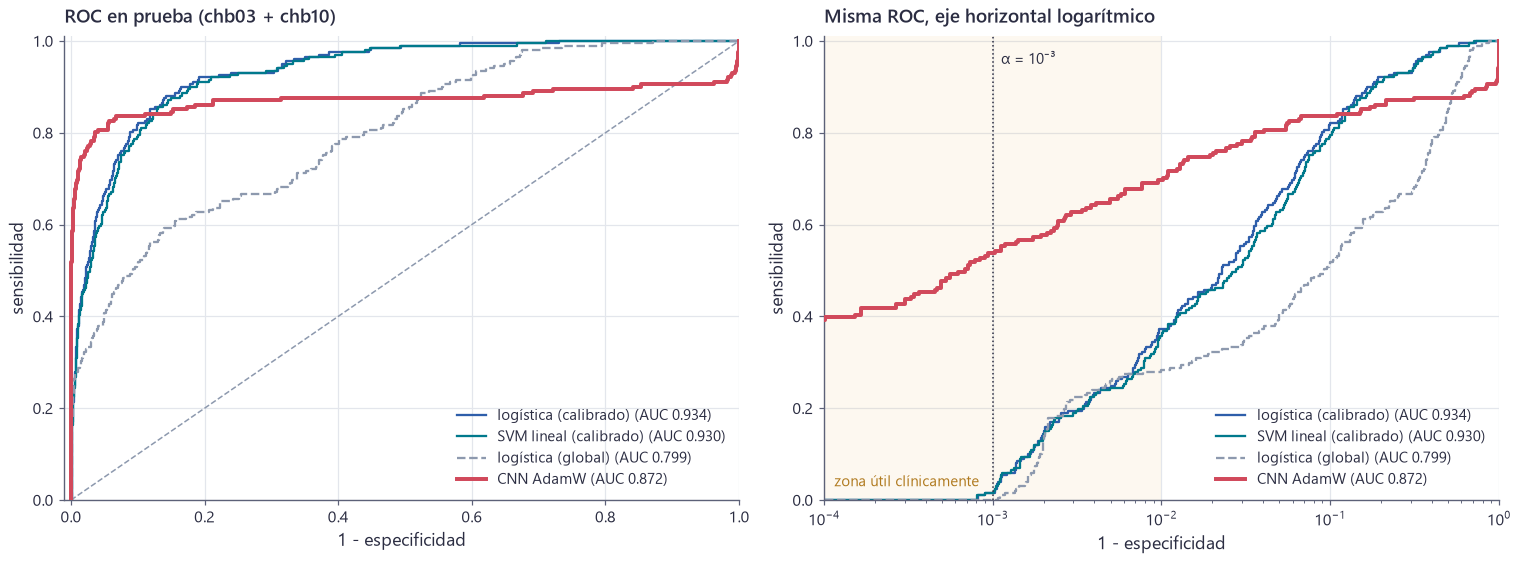

In [15]:
s3 = np.load(RAIZ / "resultados" / "etapa3" / "chbmit_scores_prueba_fija.npz")
Z = np.load(RAIZ / "datos" / "chbmit_proc" / "chbmit_bandas.npz")
idx3 = s3["indices_prueba"]
assert np.array_equal(Z["archivo"][idx3], te["archivo"]) and np.array_equal(Z["t0"][idx3], te["t0"])
limpio = te["borde"] == 0
y_te = te["ictal"][limpio]

fig, ejes = plt.subplots(1, 2, figsize=(14, 5.3))
curvas = {"logística (calibrado)": s3["calibrado__logistica"], "SVM lineal (calibrado)": s3["calibrado__svm_lineal"],
          "logística (global)": s3["global__logistica"], f"CNN {opt_final}": st_cnn}
colores_roc = [EG.AZUL, EG.VERDE, EG.GRIS, EG.ROJO]
for (nombre_c, s), col in zip(curvas.items(), colores_roc):
    fpr, tpr, _ = roc_curve(y_te, s[limpio])
    for ax in ejes:
        ax.plot(fpr, tpr, lw=2.6 if "CNN" in nombre_c else 1.5, color=col, zorder=3 if "CNN" in nombre_c else 2,
                ls="--" if "global" in nombre_c else "-",
                label=f"{nombre_c} (AUC {roc_auc_score(y_te, s[limpio]):.3f})")
ejes[0].plot([0, 1], [0, 1], ls="--", c=EG.GRIS, lw=1)
ejes[0].set_xlim(-0.01, 1); ejes[0].set_ylim(0, 1.01)
ejes[0].set_title("ROC en prueba (chb03 + chb10)")
ejes[1].set_xscale("log"); ejes[1].set_xlim(1e-4, 1); ejes[1].set_ylim(0, 1.01)
ejes[1].axvspan(1e-4, 1e-2, color=EG.AMARILLO, alpha=0.08, lw=0)
ejes[1].axvline(1e-3, c=EG.TINTA, ls=":", lw=1); ejes[1].text(1.12e-3, 0.95, "α = 10⁻³", fontsize=10, color=EG.TINTA)
ejes[1].text(1.15e-4, 0.03, "zona útil clínicamente", fontsize=9.5, color="#B07A1F")
ejes[1].set_title("Misma ROC, eje horizontal logarítmico")
for ax in ejes:
    ax.set_xlabel("1 - especificidad"); ax.set_ylabel("sensibilidad"); ax.legend(fontsize=9.5, loc="lower right")
fig.tight_layout(); fig.savefig(SALIDA / "roc_cnn_vs_convexos.png")

**Observaciones:**
- **El AUC de la CNN (0,872) es menor que el de la logística calibrada (0,934), pero la CNN es mucho
  mejor donde importa.** Con 0,1 % de falsos positivos ($\alpha = 10^{-3}$), la CNN detecta el 54 % de
  las ventanas con crisis y la logística casi ninguna. Con 0,01 % de falsos positivos la CNN todavía
  detecta el 40 %.
- La curva de la CNN queda **plana en 0,87** entre 10 % y 100 % de falsos positivos: cerca del 13 % de
  las ventanas con crisis (las de chb03_34 a chb03_36) tienen un puntaje **más bajo que la mayoría de
  las ventanas normales**. Eso hunde el AUC aunque no afecte la zona útil.
- El AUC promedia toda la curva y le da el mismo peso a la zona de 50 % de falsos positivos (inservible
  en un monitor) que a la de 0,1 %. Para detección de crisis conviene informar la sensibilidad con una
  tasa fija de falsos positivos, o el AUC parcial en $\text{FPR} \le 10^{-2}$.

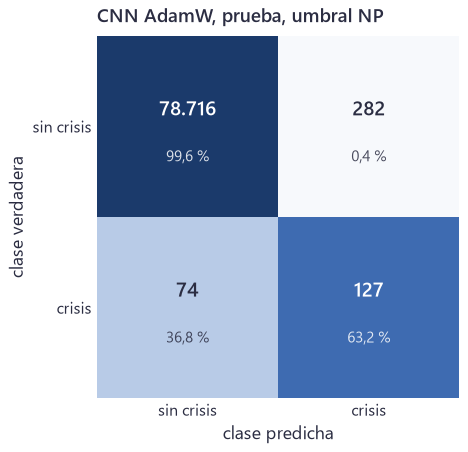

In [16]:
fig, ax = plt.subplots(figsize=(5, 4.3))
cm = confusion_matrix(y_te, pred_cnn[limpio])
EG.matriz_confusion(ax, cm, ["sin crisis", "crisis"], f"CNN {opt_final}, prueba, umbral NP")
fig.tight_layout(); fig.savefig(SALIDA / "confusion_cnn.png")

## 4.7 Curva sensibilidad por evento contra falsas alarmas por hora

Variando $\alpha$ en el umbral de Neyman-Pearson se obtiene el compromiso clínico completo.

,alfa,sens_eventos,FA_por_hora,latencia_mediana_s,modelo
0,0.00003,0.500,0.000,24.0,CNN
1,0.00010,0.571,0.000,31.0,CNN
2,0.00030,0.714,0.194,19.5,CNN
3,0.00100,0.786,1.356,11.0,CNN
4,0.00300,0.929,3.714,10.0,CNN
5,0.01000,0.929,8.408,6.0,CNN
6,0.03000,1.000,15.232,5.0,CNN
0,0.00003,0.286,0.285,41.0,logística
1,0.00010,0.357,0.433,34.0,logística
2,0.00030,0.429,0.535,35.0,logística


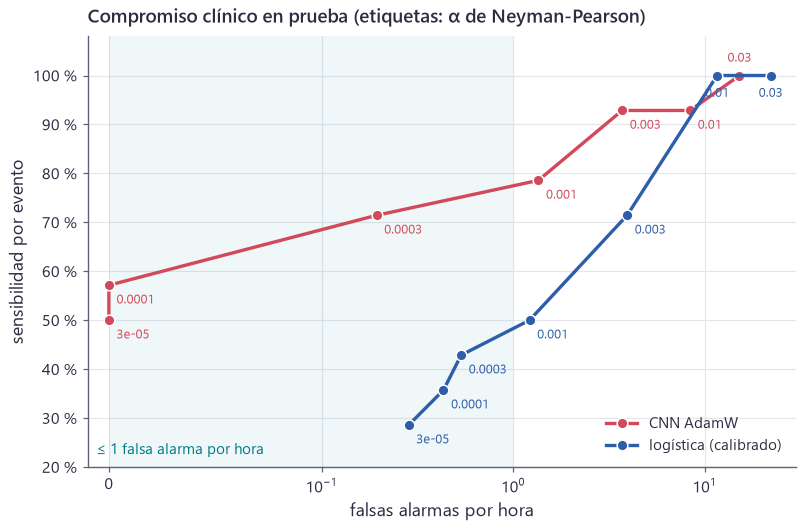

In [17]:
ALFAS = [3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2]
def barrido(s_val, s_te, va_arch=None):
    out = []
    for a in ALFAS:
        r, *_ = evaluar_cnn(s_val, s_te, alfa=a)
        out.append({"alfa": a, "sens_eventos": r["sens_eventos"], "FA_por_hora": r["FA_por_hora"],
                    "latencia_mediana_s": r["latencia_mediana_s"]})
    return pd.DataFrame(out)

curva_cnn = barrido(S["val"], S["prueba"])
curva_cnn.to_csv(SALIDA / "barrido_alfa_cnn.csv", index=False, float_format="%.4g")

# Para la logística calibrada se reentrena con la misma receta de la Etapa 3 para tener los puntajes de validación.
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
Xc = Z["bp"].reshape(len(Z["bp"]), -1).copy()
for p in np.unique(Z["paciente"]):
    Xc[Z["paciente"] == p] -= np.median(Xc[Z["paciente"] == p], axis=0)
part = json.loads((RAIZ / "datos" / "chbmit_proc" / "particion.json").read_text(encoding="utf-8"))["fija"]
m_tr = np.isin(Z["paciente"], part["entrenamiento"]) & (Z["borde"] == 0)
m_va = np.isin(Z["paciente"], part["validacion"])
lg = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight="balanced", max_iter=3000)).fit(Xc[m_tr], Z["ictal"][m_tr])
assert np.array_equal(Z["archivo"][m_va], V["validacion"]["archivo"])
curva_log = barrido(lg.decision_function(Xc[m_va]), lg.decision_function(Xc[idx3]))
curva_log.to_csv(SALIDA / "barrido_alfa_logistica.csv", index=False, float_format="%.4g")

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.axvspan(0, 1, color=EG.VERDE, alpha=0.06, lw=0)
ax.text(0.012, 0.03, "≤ 1 falsa alarma por hora", transform=ax.transAxes, fontsize=9.5, color=EG.VERDE)
for nombre_c, c, col in [(f"CNN {opt_final}", curva_cnn, EG.ROJO), ("logística (calibrado)", curva_log, EG.AZUL)]:
    ax.plot(c.FA_por_hora, c.sens_eventos, "o-", color=col, label=nombre_c, lw=2.2, ms=7,
            markeredgecolor="white", markeredgewidth=1)
    for _, r in c.iterrows():
        arriba = r.sens_eventos >= 0.999
        ax.annotate(f"{r.alfa:g}", (r.FA_por_hora, r.sens_eventos), fontsize=8.5, color=col,
                    xytext=(0, 9 if col == EG.ROJO else -14) if arriba else (5, -12),
                    ha="center" if arriba else "left", textcoords="offset points")
ax.set_xscale("symlog", linthresh=0.1); ax.set_xlim(-0.01, 30); ax.set_ylim(0.2, 1.08)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.0f} %"))
ax.set_xlabel("falsas alarmas por hora"); ax.set_ylabel("sensibilidad por evento")
ax.set_title("Compromiso clínico en prueba (etiquetas: α de Neyman-Pearson)"); ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(SALIDA / "sensibilidad_vs_falsas_alarmas.png")
pd.concat([curva_cnn.assign(modelo="CNN"), curva_log.assign(modelo="logística")]).round(
    {"sens_eventos": 3, "FA_por_hora": 3, "latencia_mediana_s": 1})

**Observaciones:**
- **La CNN domina a la logística en toda la zona de pocas falsas alarmas.** Con $\alpha = 3\cdot10^{-4}$
  detecta 10 de 14 crisis (71 %) con **0,19 falsas alarmas por hora** (una cada 5 horas); con
  $\alpha = 10^{-4}$ detecta 8 de 14 sin ninguna falsa alarma en 88 horas. La logística, para detectar
  el 43 %, ya da 0,54 por hora.
- **La CNN también avisa antes:** con $\alpha = 10^{-3}$, latencia mediana de 11 s contra 26 s.
- El compromiso es el que predice Neyman-Pearson: al aflojar la restricción ($\alpha$ más grande) sube la
  sensibilidad y suben las falsas alarmas. Detectar el 100 % de las crisis cuesta 15 falsas alarmas por
  hora con la CNN y 12 con la logística, inaceptable en ambos casos.
- Las falsas alarmas reales en prueba son del orden de lo que fija $\alpha$ (900 ventanas por hora ×
  $10^{-3}$ ≈ 0,9 ventanas por hora, y una alarma puede abarcar varias ventanas). Igual que en la Etapa 3,
  no coincide exactamente porque el umbral se calcula con otro paciente.

## 4.8 Guardado

In [18]:
meta = {"arquitectura": str(E.CNN()), "parametros": int(sum(p.numel() for p in E.CNN().parameters())),
        "epocas": E.EPOCAS, "lote": E.LOTE, "neg_por_pos": E.NEG_POR_POS, "semillas": E.SEMILLAS,
        "tasas_probadas": {k: v[0] for k, v in E.OPTIMIZADORES.items()}, "tasas_elegidas": elegidas,
        "modelo_final": nombre, "torch": torch.__version__}
(SALIDA / "metadatos.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print(sorted(p.name for p in SALIDA.iterdir() if p.is_file()))

['auc_prueba_por_optimizador.png', 'barrido_alfa_cnn.csv', 'barrido_alfa_logistica.csv', 'busqueda_lr.csv', 'busqueda_lr_auc_prueba.csv', 'busqueda_lr_curvas.png', 'cnn_eventos_prueba.csv', 'cnn_por_paciente.csv', 'comparacion_final.csv', 'comparativa_optimizadores.csv', 'comparativa_tasa_alta.csv', 'confusion_cnn.png', 'curvas_optimizadores.png', 'etapa4_busqueda.log', 'etapa4_semillas.log', 'lr_elegidas.json', 'mann_whitney.csv', 'mann_whitney_tasa_alta.csv', 'metadatos.json', 'percentil_por_crisis.csv', 'percentil_por_crisis.png', 'posthoc.log', 'roc_cnn_vs_convexos.png', 'sensibilidad_vs_falsas_alarmas.png', 'tasa_elegida_vs_alta.png', 'validacion_vs_prueba.png', 'ventanas_entrenamiento.npz', 'ventanas_prueba.npz', 'ventanas_validacion.npz']
